In [1]:
!pip install -q "torchao>=0.16.0"
!pip install -q --upgrade peft
!pip install -q transformers datasets

In [2]:
import peft
import torchao
print(f"peft version: {peft.__version__}")
print(f"torchao version: {torchao.__version__}")

W1115 13:22:01.674000 7098 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 13:22:01.739000 7098 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


peft version: 0.21.3
torchao version: 0.18.0


In [3]:
import torch
print(f"GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
else:
    print("NO GPU — go to Runtime > Change runtime type > T4 GPU")

GPU available: True
GPU name: Tesla T4


In [4]:
from google.colab import files

print("A file picker will appear. Select your cebuano_corpus.txt file.")
uploaded = files.upload()

# Confirm it uploaded
import os
print(f"\nUploaded files: {list(uploaded.keys())}")
print(f"File size: {os.path.getsize('cebuano_corpus.txt'):,} bytes")

A file picker will appear. Select your cebuano_corpus.txt file.


Saving cebuano_corpus.txt to cebuano_corpus (2).txt

Uploaded files: ['cebuano_corpus (2).txt']
File size: 1,476,896 bytes


In [5]:
with open("cebuano_corpus.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print(f"Total characters : {len(raw_text):,}")
print(f"Total words      : {len(raw_text.split()):,}")
print(f"\nFirst 500 characters:")
print(raw_text[:500])

Total characters : 1,472,666
Total words      : 250,771

First 500 characters:
Gi-share sa NASA ang mga hulagway sa Phantom galaxy , usa ka grand-design spiral galaxy mga 32 million ka light-years ang gilay-on .

Gihimug-atan sa langyaw nga di lang ang maong pamilya ang iyang natabangan .

Sa comparative report sa CSBT , nasayran nga nikita ang terminal og P51,375,722.62 gikan sa Enero hangtod sa Septiyembre karong tuiga , mas dako kon itandi sa P49,053,604.28 sa susamang panahon sa 2016 ug P47,587,520.99 sa 2015 .

Ang iyang gipasabot mao si kanhi konsehal Nida Cabrera , 


In [6]:
from transformers import GPT2Tokenizer
from datasets import Dataset
import random

tokenizer = GPT2Tokenizer.from_pretrained("distilgpt2")
tokenizer.pad_token = tokenizer.eos_token

def chunk_text(text, tokenizer, chunk_size=128):
    tokens = tokenizer.encode(text)
    chunks = []
    for i in range(0, len(tokens) - chunk_size, chunk_size):
        chunks.append(tokens[i:i + chunk_size])
    return chunks

chunks = chunk_text(raw_text, tokenizer)

total_tokens = len(tokenizer.encode(raw_text))
steps_per_epoch = int(len(chunks) * 0.9) // 4

print(f"Total tokens in corpus : {total_tokens:,}")
print(f"Total chunks           : {len(chunks)}")
print(f"Train chunks (90%)     : {int(len(chunks) * 0.9)}")
print(f"Steps per epoch        : {steps_per_epoch}")
print(f"Total steps (5 epochs) : {steps_per_epoch * 5}")
print(f"Estimated time on GPU  : ~{(steps_per_epoch * 5 * 2) // 60} minutes")

# Check 3 random chunks — READ THESE before continuing
print("\n--- 3 random sample chunks ---")
print("These should look like real Cebuano text\n")
random.seed(42)
for i in random.sample(range(len(chunks)), 3):
    print(f"Chunk {i}:")
    print(tokenizer.decode(chunks[i], skip_special_tokens=True))
    print()

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (563432 > 1024). Running this sequence through the model will result in indexing errors


Total tokens in corpus : 563,432
Total chunks           : 4401
Train chunks (90%)     : 3960
Steps per epoch        : 990
Total steps (5 epochs) : 4950
Estimated time on GPU  : ~165 minutes

--- 3 random sample chunks ---
These should look like real Cebuano text

Chunk 912:
 Samtang , wala'y namatay sa kasundaluhan sa gobyerno

LALAKI PATAY HUMAN GITIGBAS SA PAMPLONA Usa ka lalaki ang gitigbas patay sa Barangay Abante sa lungsod sa Pamplona niadtong Martes sa gabii , Hulyo 26 , 2022. Giila ang biktima nga si Reymark Torres , 19 anyos , ug lumolupyo sa Sitio Talay sa naasoy nga lugar. Padayon

Chunk 204:
 gitaod sa ilang sakyanan ilabi na sa mga dagkong kalihukan alang sa seguridad niini .

Tanang klase sa sugal iyang naagian .

Apan giingong wa makadawat si Quindala , gani kanunay kini nga mohangyo nga ma­kigbalik ug mohangyo nga makighilawas .

Matod ni SPO2 Yvonne Illustrisimo , ang duha nalambigit sa

Chunk 2253:
a ka adlaw samtang papauli ko gikan sa eskwelahan, natalang ko sa akon

In [7]:
dataset = Dataset.from_dict({"input_ids": chunks})
dataset = dataset.train_test_split(test_size=0.1, seed=42)

print(f"Train : {len(dataset['train'])} chunks")
print(f"Test  : {len(dataset['test'])} chunks")

Train : 3960 chunks
Test  : 441 chunks


In [8]:
from transformers import GPT2LMHeadModel, DataCollatorForLanguageModeling
from peft import get_peft_model, LoraConfig, TaskType

model = GPT2LMHeadModel.from_pretrained("distilgpt2")

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["c_attn"],
    bias="none",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

trainable params: 147,456 || all params: 82,060,032 || trainable%: 0.1797


/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


In [9]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="/content/checkpoints/lora_step1",
    num_train_epochs=5,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    save_steps=100,
    logging_steps=20,
    learning_rate=5e-5,
    warmup_steps=30,
    fp16=True,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    data_collator=data_collator,
)

print("Training started — watch the loss numbers below")
print("They should generally go DOWN over time\n")
trainer.train()
print("\nTraining complete!")

Training started — watch the loss numbers below
They should generally go DOWN over time



[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
20,5.759057
40,5.786245
60,5.685900
80,5.667544
100,5.599963
120,5.628203
140,5.491018
160,5.507331
180,5.470762
200,5.443004



Training complete!


In [10]:
model.save_pretrained("/content/checkpoints/lora_step1")
tokenizer.save_pretrained("/content/checkpoints/lora_step1")

import os
files_saved = os.listdir("/content/checkpoints/lora_step1")
print(f"Checkpoint saved. Files: {files_saved}")

Checkpoint saved. Files: ['README.md', 'checkpoint-2000', 'checkpoint-2300', 'tokenizer.json', 'adapter_model.safetensors', 'checkpoint-200', 'checkpoint-400', 'checkpoint-1900', 'checkpoint-1100', 'checkpoint-1400', 'adapter_config.json', 'checkpoint-1000', 'checkpoint-1500', 'checkpoint-300', 'checkpoint-1200', 'checkpoint-2400', 'checkpoint-1700', 'checkpoint-900', 'checkpoint-1800', 'checkpoint-500', 'checkpoint-1300', 'checkpoint-700', 'checkpoint-800', 'tokenizer_config.json', 'checkpoint-100', 'checkpoint-2100', 'checkpoint-1600', 'checkpoint-2200', 'checkpoint-600', 'checkpoint-2475']


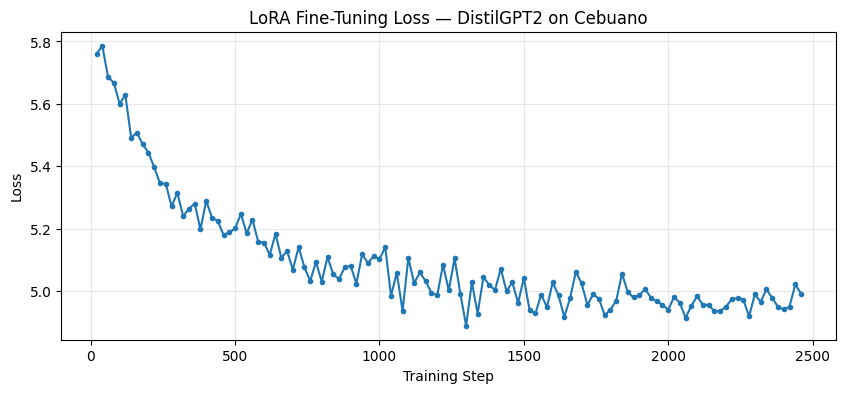

Start loss  : 5.7591
Final loss  : 4.9917
Improvement : 0.7673


In [11]:
import matplotlib.pyplot as plt

log_history = trainer.state.log_history
train_loss = [(x['step'], x['loss']) for x in log_history if 'loss' in x]
steps, losses = zip(*train_loss)

plt.figure(figsize=(10, 4))
plt.plot(steps, losses, marker='o', markersize=3)
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("LoRA Fine-Tuning Loss — DistilGPT2 on Cebuano")
plt.grid(True, alpha=0.3)
plt.savefig("/content/loss_curve.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"Start loss  : {losses[0]:.4f}")
print(f"Final loss  : {losses[-1]:.4f}")
print(f"Improvement : {losses[0] - losses[-1]:.4f}")

In [12]:
from peft import PeftModel
from transformers import GPT2LMHeadModel
import torch
import json

# Reload both models
base_model = GPT2LMHeadModel.from_pretrained("distilgpt2")
base_model.eval()

ft_base = GPT2LMHeadModel.from_pretrained("distilgpt2")
ft_model = PeftModel.from_pretrained(
    ft_base,
    "/content/checkpoints/lora_step1"
)
ft_model.eval()

# Fixed generation function
def generate(model, prompt, max_new_tokens=80):
    inputs = tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        output = model.generate(
            inputs["input_ids"],
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            repetition_penalty=1.3,
            no_repeat_ngram_size=3,
        )
    return tokenizer.decode(output[0], skip_special_tokens=True)

prompts = [
    "Ang mga estudyante sa Cebu",
    "Nagsugod na ang",
    "Ang kinabuhi sa",
    "Miadto siya sa merkado",
    "Sa matag adlaw ang mga tawo",
]

results = {}

print("=" * 65)
print("BEFORE vs AFTER — FIXED")
print("=" * 65)

for prompt in prompts:
    before = generate(base_model, prompt)
    after  = generate(ft_model,   prompt)
    results[prompt] = {"before": before, "after": after}

    print(f"\nPROMPT : {prompt}")
    print(f"BEFORE : {before}")
    print(f"AFTER  : {after}")
    print("-" * 65)

# Save fixed results
with open("/content/before_after_results_fixed.json", "w",
          encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("\nSaved.")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

BEFORE vs AFTER — FIXED

PROMPT : Ang mga estudyante sa Cebu
BEFORE : Ang mga estudyante sa Cebu.
The first time I saw a man in the street, he was wearing an orange shirt and black pants with his head covered up like it's been for years now (I'm not sure if that is true). He had no idea what to do but said: "You're going on this." The next day we went out of our way so they were able get us there by car or
AFTER  : Ang mga estudyante sa Cebuyan.
Nagatay ang nakapang kunga ni thean-admantalong .

Mingo ka pagkon, si ako na giitos , ug pinyas ng bahinot ognaw ko diktigod pa lianabayan yipunaga siya ushoy tala mags
-----------------------------------------------------------------

PROMPT : Nagsugod na ang
BEFORE : Nagsugod na angi ng nga kaputin.
The government has said it will not allow the sale of a new car to anyone who is in need, but that would be an issue for all drivers and dealerships across Malaysia as well.
AFTER  : Nagsugod na ang mga nagtakon sa kapatang.


Pawayo ni NAGTAN , 

In [14]:
from google.colab import files
import shutil

# Download loss curve
files.download("/content/loss_curve.png")

# Download before/after results
files.download("/content/before_after_results.json")

# Zip and download checkpoint
print("Zipping checkpoint — this may take a moment...")
shutil.make_archive(
    "/content/lora_step1_checkpoint",
    "zip",
    "/content/checkpoints/lora_step1"
)
files.download("/content/lora_step1_checkpoint.zip")

print("All files downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Zipping checkpoint — this may take a moment...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All files downloaded.
